# Data Check: Vol / Spread

Quick visual check for the `ExectuionPriceDerived` pipeline stage data quality.

1. Run the `ExectuionPriceDerived` pipeline stage to populate parquet data
2. Load and inspect `volatility_ema`, `spread_pct_ema`, `bid`, `ask` from `VolSpreadStore`
3. Plot vol/spread ratio with reference lines and print distribution statistics

## Setup

In [8]:
import sys
sys.path.insert(0, '../../src')

import logging
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from makalu import settings as sys_env
from makalu.storage.parquet_store import ParquetStore
from qate.util.dt_range import DtRange

from feature_engineering.volatility import VolSpreadConfig
from pipeline.market_pair import EXECUTION_SIZE, LEAD_LAG_PAIRS

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
sns.set_style('whitegrid')
%matplotlib inline

# logging.basicConfig(level=logging.INFO, format='%(asctime)s %(name)s %(levelname)s %(message)s')

POPULATE_DATA = False

PAIR_KEY = 'btc'
MARKET_LEAD, MARKET_LAG = LEAD_LAG_PAIRS[PAIR_KEY]
DATA_START_DATE = '20260101'
DATA_END_DATE   = '20260215'

DT_RANGE = DtRange.from_strings(DATA_START_DATE, DATA_END_DATE)
EXECUTION_SIZE_STR = EXECUTION_SIZE.get(MARKET_LEAD.symbol)
CONFIG = VolSpreadConfig(
    return_shift_sec=300,
    lookback_sec=900,
    ema_span_sec=900,
)

print(f'Market (lead):  {MARKET_LEAD.id}')
print(f'Market (lag):   {MARKET_LAG.id}')
print(f'Date range:     {DATA_START_DATE} - {DATA_END_DATE}')
print(f'Execution size: {EXECUTION_SIZE_STR}')
print(f'VolSpread config: {CONFIG}')
print(f'param_id:       {CONFIG.param_id}')

Market (lead):  BINANCE:BTC_USDT
Market (lag):   GMO:BTC_JPY
Date range:     20260101 - 20260215
Execution size: 0.002
VolSpread config: VolSpreadConfig(return_shift_sec=300, lookback_sec=900, ema_span_sec=900, resample_interval='1s')
param_id:       vs_300_900_900_1s


## 1. Run Pipeline

In [9]:
from k2_data.store import MarketDataStore

from pipeline.framework import Pipeline
from pipeline.stages import ExecutionPriceDerivedStage
from pipeline.execution_price_derived_steps import VolSpreadStep

def populate_data(market):
    execution_size_str = EXECUTION_SIZE.get(market.symbol)
    market_data_store = MarketDataStore(sys_env.get_market_data_dir())
    parquet_store = ParquetStore(sys_env.get_parquet_root_dir())

    pipeline = Pipeline(market_data_store, parquet_store)
    pipeline.stage(
        ExecutionPriceDerivedStage(market, execution_size_str)
        .step(VolSpreadStep(CONFIG))
    )

    print(f'Running pipeline for {market.id}...')
    pipeline.process(DT_RANGE)
    print('Done.')

if POPULATE_DATA:
    # populate_data(MARKET_LEAD)
    populate_data(MARKET_LAG)

## 2. Load & Inspect Parquet Data

In [10]:
store = ParquetStore(sys_env.get_parquet_root_dir())

# lead_df = store.create_vol_spread(MARKET_LEAD, EXECUTION_SIZE.get(MARKET_LEAD.symbol), CONFIG.param_id).read(DT_RANGE)
#
# print(f'Lead ({MARKET_LEAD.id}):')
# print(f'  Shape:      {lead_df.shape}')
# print(f'  Columns:    {list(lead_df.columns)}')
# print(f'  Time range: {lead_df.index.min()} ~ {lead_df.index.max()}')
# print(f'  NaN counts: {lead_df.isna().sum().to_dict()}')
# display(lead_df.describe().T)

lag_df  = store.create_vol_spread(MARKET_LAG,  EXECUTION_SIZE.get(MARKET_LAG.symbol),  CONFIG.param_id).read(DT_RANGE)

print(f'\nLag ({MARKET_LAG.id}):')
print(f'  Shape:      {lag_df.shape}')
print(f'  Columns:    {list(lag_df.columns)}')
print(f'  Time range: {lag_df.index.min()} ~ {lag_df.index.max()}')
print(f'  NaN counts: {lag_df.isna().sum().to_dict()}')
display(lag_df.describe().T)


Lag (GMO:BTC_JPY):
  Shape:      (8158414, 8)
  Columns:    ['ts', 'bid', 'ask', 'mid', 'spread', 'spread_bps', 'volatility_ema', 'spread_pct_ema']
  Time range: 0 ~ 8158413
  NaN counts: {'ts': 0, 'bid': 0, 'ask': 0, 'mid': 0, 'spread': 0, 'spread_bps': 0, 'volatility_ema': 0, 'spread_pct_ema': 0}


,count,mean,std,min,25%,50%,75%,max
ts,8158414.0,1.769176e+09,1.152522e+06,1.767193e+09,1.768173e+09,1.769167e+09,1.770180e+09,1.771168e+09
bid,8158414.0,1.318772e+07,1.622938e+06,9.407564e+06,1.181643e+07,1.387434e+07,1.433890e+07,1.552988e+07
ask,8158414.0,1.319136e+07,1.622772e+06,9.408480e+06,1.182012e+07,1.387789e+07,1.434239e+07,1.553000e+07
mid,8158414.0,1.318954e+07,1.622855e+06,9.408022e+06,1.181834e+07,1.387610e+07,1.434068e+07,1.552994e+07
spread,8158414.0,3.642311e+03,1.337273e+03,1.000000e+00,2.722000e+03,3.675000e+03,4.565000e+03,1.486300e+04
spread_bps,8158414.0,2.823295e+00,1.144459e+00,6.548789e-04,2.029020e+00,2.783006e+00,3.548029e+00,9.996073e+00
volatility_ema,8158414.0,1.095422e-03,9.928843e-04,0.000000e+00,4.660231e-04,8.054729e-04,1.383984e-03,1.154731e-02
spread_pct_ema,8158414.0,2.822874e-04,7.226562e-05,5.153583e-05,2.348260e-04,2.751291e-04,3.243996e-04,7.005536e-04


## 3. Vol / Spread Ratio Over Time

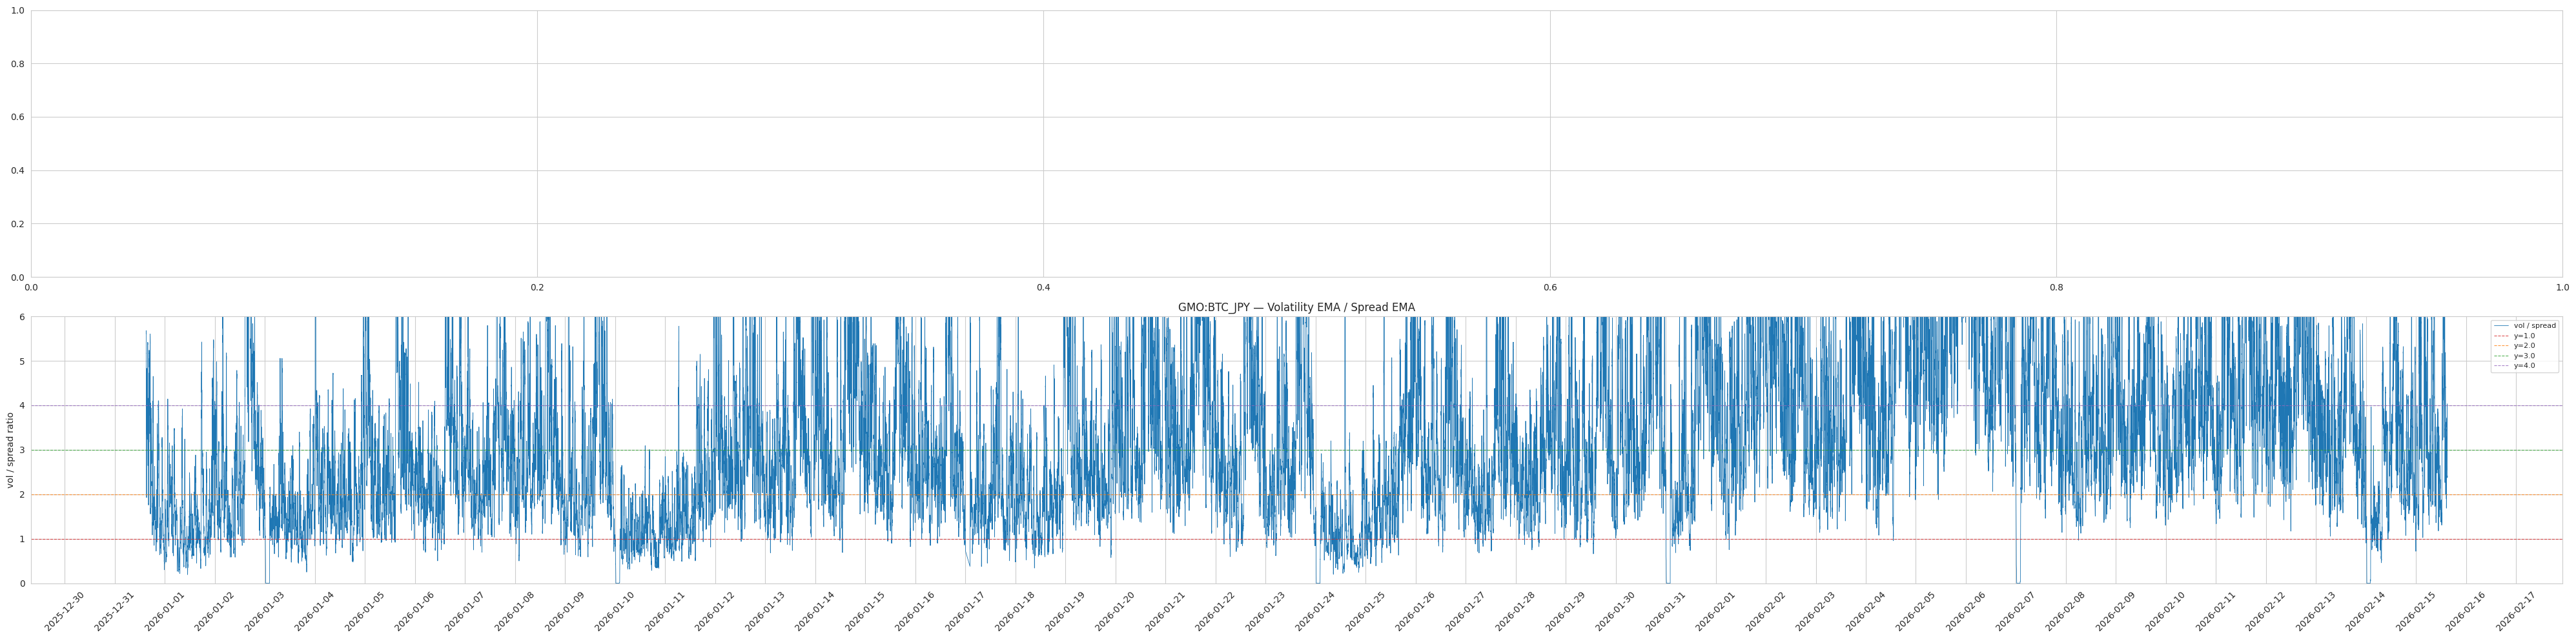

In [11]:
import matplotlib.dates as mdates

def plot_vol_spread_ratio(df, market_id, ax):
    dt = pd.to_datetime(df['ts'], unit='s')
    ratio = df['volatility_ema'] / df['spread_pct_ema']
    ax.plot(dt, ratio, color='tab:blue', linewidth=0.6, label='vol / spread')
    for level, color in [(1.0, 'tab:red'), (2.0, 'tab:orange'), (3.0, 'tab:green'), (4.0, 'tab:purple')]:
        ax.axhline(y=level, color=color, linestyle='--', linewidth=0.8, alpha=0.8, label=f'y={level:.1f}')
    ax.set_ylim(bottom=0, top=6)
    ax.set_ylabel('vol / spread ratio')
    ax.set_title(f'{market_id} — Volatility EMA / Spread EMA')
    ax.legend(loc='upper right', fontsize=8)
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
    ax.tick_params(axis='x', rotation=45)

fig, axes = plt.subplots(2, 1, figsize=(40, 10), sharex=False)
# plot_vol_spread_ratio(lead_df, MARKET_LEAD.id, axes[0])
plot_vol_spread_ratio(lag_df,  MARKET_LAG.id,  axes[1])
plt.tight_layout()
plt.show()

## 4. Spread EMA and Volatility EMA Over Time

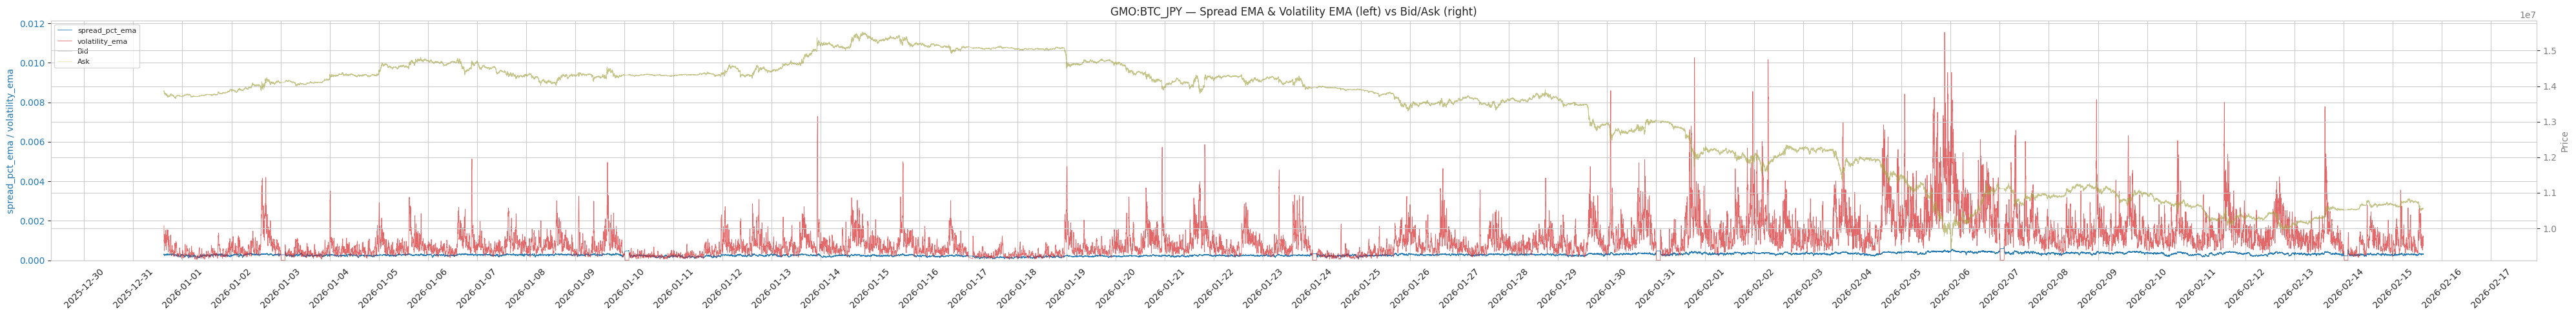

In [12]:
def plot_vol_and_spread(df, market_id):
    dt = pd.to_datetime(df['ts'], unit='s')
    fig, ax1 = plt.subplots(figsize=(40, 5))
    ax1.set_ylabel('spread_pct_ema / volatility_ema', color='tab:blue')
    ax1.plot(dt, df['spread_pct_ema'], color='tab:blue',  linewidth=0.6, label='spread_pct_ema')
    ax1.plot(dt, df['volatility_ema'], color='tab:red',   linewidth=0.6, alpha=0.7, label='volatility_ema')
    ax1.tick_params(axis='y', labelcolor='tab:blue')
    ax1.set_ylim(bottom=0)

    ax2 = ax1.twinx()
    ax2.set_ylabel('Price', color='tab:gray')
    ax2.plot(dt, df['bid'], color='tab:gray',  linewidth=0.5, alpha=0.4, label='Bid')
    ax2.plot(dt, df['ask'], color='tab:olive', linewidth=0.5, alpha=0.4, label='Ask')
    ax2.tick_params(axis='y', labelcolor='tab:gray')

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=8)

    ax1.set_title(f'{market_id} — Spread EMA & Volatility EMA (left) vs Bid/Ask (right)')
    ax1.xaxis.set_major_locator(mdates.DayLocator(interval=1))
    ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
    ax1.tick_params(axis='x', rotation=45)
    fig.tight_layout()
    plt.show()

# plot_vol_and_spread(lead_df, MARKET_LEAD.id)
plot_vol_and_spread(lag_df,  MARKET_LAG.id)

## 5. Distribution Statistics

In [13]:
def print_stats(df, market_id):
    ratio = df['volatility_ema'] / df['spread_pct_ema']
    total = len(ratio)
    print(f'=== {market_id} ===')
    print(f'Total ticks:          {total:,}')
    print(f'Mean spread_pct_ema:  {df["spread_pct_ema"].mean():.6f}  ({df["spread_pct_ema"].mean() * 10000:.4f} bps)')
    print(f'Mean volatility_ema:  {df["volatility_ema"].mean():.6f}  ({df["volatility_ema"].mean() * 10000:.4f} bps)')
    print()
    print('vol/spread threshold  | count      | pct')
    print('----------------------|------------|--------')
    for level in [1.0, 2.0, 3.0, 4.0]:
        n = (ratio > level).sum()
        print(f'  > {level:.1f}               | {n:>10,} | {n / total:.1%}')
    print()

# print_stats(lead_df, MARKET_LEAD.id)
print_stats(lag_df,  MARKET_LAG.id)

=== GMO:BTC_JPY ===
Total ticks:          8,158,414
Mean spread_pct_ema:  0.000282  (2.8229 bps)
Mean volatility_ema:  0.001095  (10.9542 bps)

vol/spread threshold  | count      | pct
----------------------|------------|--------
  > 1.0               |  7,695,123 | 94.3%
  > 2.0               |  5,953,966 | 73.0%
  > 3.0               |  4,055,936 | 49.7%
  > 4.0               |  2,634,647 | 32.3%



## 6. Data Consistency Summary

In [14]:
print('=' * 60)
print('Data Consistency Summary')
print('=' * 60)

for market, df in [
    # (MARKET_LEAD, lead_df),
    (MARKET_LAG, lag_df),
]:
    print(f'\n--- {market.id} ---')
    print(f'  Rows:       {len(df):,}')
    print(f'  Columns:    {list(df.columns)}')
    print(f'  Time range: {df.index.min()} ~ {df.index.max()}')
    total_nan = df.isna().sum().sum()
    print(f'  Total NaN:  {total_nan:,} ({total_nan / max(df.size, 1) * 100:.2f}%)')
    dupes = df.index.duplicated().sum()
    print(f'  Duplicate timestamps: {dupes}')
    print(f'  Monotonic index:      {df.index.is_monotonic_increasing}')

    # Sanity checks
    print(f'  bid <= ask:           {(df["bid"] <= df["ask"]).all()}')
    print(f'  volatility_ema >= 0:  {(df["volatility_ema"] >= 0).all()}')
    print(f'  spread_pct_ema > 0:   {(df["spread_pct_ema"] > 0).all()}')

Data Consistency Summary

--- GMO:BTC_JPY ---
  Rows:       8,158,414
  Columns:    ['ts', 'bid', 'ask', 'mid', 'spread', 'spread_bps', 'volatility_ema', 'spread_pct_ema']
  Time range: 0 ~ 8158413
  Total NaN:  0 (0.00%)
  Duplicate timestamps: 0
  Monotonic index:      True
  bid <= ask:           True
  volatility_ema >= 0:  True
  spread_pct_ema > 0:   True
